In [4]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist

Call the datastets from mnist

In [6]:
(train_images,train_labels),(test_images,test_labels) = mnist.load_data()

In [7]:
train_images=(train_images/255.0) -0.5
test_images=(test_images/255.0) -0.5

print(train_images.shape)
print(test_images.shape)

(60000, 28, 28)
(10000, 28, 28)


The train images folder has 60000 images of pixel dimensions 28x28 \
The test images folder has 10000 images of pixels 20x20 \
Adding a third dimensions because kers CNN needs it

In [8]:
train_images=np.expand_dims(train_images,axis=3)
test_images=np.expand_dims(test_images,axis=3)
print(train_images.shape)
print(test_images.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


Importing the necessary functions from keras for the CNN

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Dense,Flatten

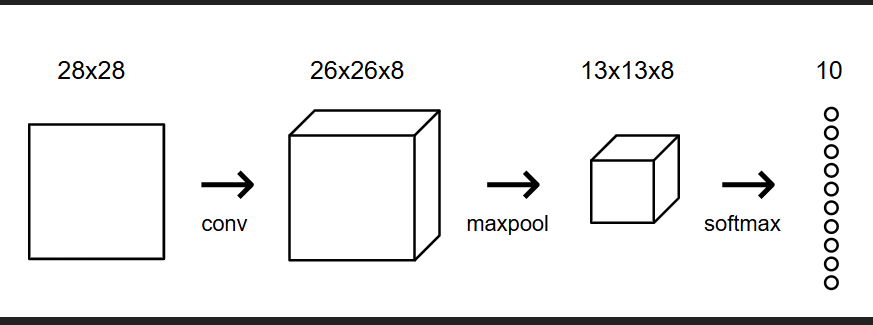

In [13]:
#parameters for the model
num_filters=8
filter_size=3
pool_size=2

#bulding the model
model=Sequential([
    keras.Input(shape=(28,28,1)),
    Conv2D(num_filters,filter_size),
    MaxPooling2D(pool_size=pool_size),
    Flatten(),
    Dense(10,activation='softmax')
])

Building the above neural network architecture \
taking the input of 28x28x1 pixels of my images \
then performing Conv function, as an inputs i add the num_filters=8 this will \
be the number of filters that i will use buidling an 8-channel feature map for the CNN  , and the filter_size \ as the dimensions of my window that will go around the 28x28x1 image\
The output will be a 8 26x26 stacked pixels images so 26x26x8.\

The 26 comes form the fact that my window will detect how many pixels area the 3x3 window can fit , because i have a 3x3 window so 3 pixels on x axis and 3 \
on y the result will be from the pixel corners (1,3),(3,1) to pixel (28,28) \ so 26 total pixel covers

Then i will  perform the maxpool with size of 2 . This will shrink the dimensions of my pixel images form 26x26x8 to 13x13x8 since i have the shrink factor pool_size=2.

Finally, i perform the Flatten function , as shown in the image this will turn the 13x13x8 to a 1D array of 13*13*8=1352 elements , te total final number of pixels, and i will turn that into my neuron output using the Dense function.

As shown in the code i will have a total of 10 output neurons , so each of this 1352 pixels i have will be connected to these 10 outputs.

Each connection will have weights that are described by the equations:
$$w_j=\sum_{i=1}^{1352} w_{ij}x_i +b_j \forall j \in [0,1,\cdots ,9]$$
So the total amount of connections will be $1352 \cdot 10 +10=13530$ trainable parameters.

Each of the 10 outputs has a score , i need to convert this score to a number from 0 to 1 , i can do that using the softmax functions:
$$softmax(z_j)=\frac{ e^{z_j} } {\sum_{k=0}^9 e^{z_k}}$$

In [15]:
#compiling the program
model.compile(
  'adam',
  loss='categorical_crossentropy',
  metrics=['accuracy']
)

In [17]:
from tensorflow.keras.utils import to_categorical

Initializing the CNN training, the train_images,train_labels will be used for the training and the test_images, test_labels will be used for the testing of my accuracy

In [18]:
model.fit(
  train_images,
  to_categorical(train_labels),
  epochs=3,
  validation_data=(test_images, to_categorical(test_labels)),
)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.9041 - loss: 0.3357 - val_accuracy: 0.9498 - val_loss: 0.1776
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9545 - loss: 0.1605 - val_accuracy: 0.9626 - val_loss: 0.1278
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.9642 - loss: 0.1252 - val_accuracy: 0.9662 - val_loss: 0.1153


The model.ft train my CNN , the training is performed with the train images,labels , the to_categorical function is used to initialize one-hot encoded vectors in my labels , for example label 3 becomes [0,0,0,1,0,0,0,0,0,0]. This happens in order to better match the output of the training with the result of the test images,labels. The accuracy will connect the label of the image to the 10 neuran softmax output that was initialized before to a scale from 0 to 1. The epochs says that the model will go throught the train_images 3 times to increase my accuracy. After each epoch i test the results of th training wiht my validations data (my test images,labels)

In [25]:
#saving the model wieghts , now i can call the trainined model
model.save_weights('cnn.weights.h5')

In [27]:
#call the weights data of my trained model
model.load_weights('cnn.weights.h5')

In [31]:
#predictions for first 5 test images
predictions=model.predict(test_images[:5])
print(np.argmax(predictions,axis=1))
print(test_labels[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
[7 2 1 0 4]
[7 2 1 0 4]
